# 04. Job Description Cleaning & Section-Aware Preprocessing
**AI-Based Resume–Job Matching & Skill Gap Analysis — Phase 6B**

### Background & Objective:
In **Phase 5 (Error Analysis)** and **Phase 6A (Supervised Multi-Signal Classifier)**, two critical diagnostic findings emerged regarding job descriptions:
1. **Length Distortion**: Job descriptions in misclassified pairs were substantially longer (mean ~371 words, median 313 words) than true matches, heavily laden with corporate boilerplate (EEO statements, company history blurbs, benefits packages, application disclaimers).
2. **Dominant Length Features**: Document word/char counts and ratio features became some of the strongest predictors in the supervised classifier, compensating for bloated job postings.

**Hypothesis**: Conservative boilerplate removal and section-aware preprocessing (`job_core_text`) will strip irrelevant legal/company text, sharpen lexical and semantic similarity between candidate resumes and true job requirements, and boost macro F1 score.

### Experimental Protocol & Guardrails:
- **Baseline Reference (Model A)**: Supervised Logistic Regression ($C=0.1$, `class_weight='balanced'`) trained on raw job descriptions (`Validation Macro F1 = 0.4603`, `Candidate Test Macro F1 = 0.4735`, `Official Test Macro F1 = 0.4220`).
- **Treated Model (Model B)**: Supervised Logistic Regression ($C=0.1$, `class_weight='balanced'`) trained with identical architecture and 22 feature definitions, but replacing raw job descriptions with cleaned/core text (`job_core_text`).
- **Leakage Safeguards**: All text cleaning rules are deterministic and rule-based. Preprocessing, TF-IDF vectorization, and `StandardScaler` are fitted **strictly on `candidate_train`**.
- **Conservative Fallback**: To prevent catastrophic information loss, a hard fallback safeguard restores the original job description if cleaned text drops below 120 characters or retains under 20% of original length.


## 1. Boilerplate Removal & Section-Aware Cleaning Architecture

We implement `clean_job_description(text)` with three sequential stages:
1. **Targeted Inline Boilerplate Removal**: Stripping ubiquitous legal/EEO disclaimers, accommodation contact notices, and staffing agency boilerplates.
2. **Heading-Based Section Extraction**: Segmenting postings by regex headings into Core sections (`CORE_SUMMARY`, `CORE_RESPONSIBILITIES`, `CORE_REQUIREMENTS`), Boilerplate sections (`BP_EEO`, `BP_COMPANY`, `BP_BENEFITS`, `BP_APPLY`), and Other content.
3. **Fallback Safeguard**: If regex parsing strips more than 80% of text or yields < 120 characters, the cleaner safely rolls back to the original unmodified text.


In [1]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Section headings definitions
HEADINGS = [
    (r'(?:job|position|role)\s+(?:summary|overview|description|details|scope)|about\s+the\s+role', 'CORE_SUMMARY'),
    (r'(?:essential\s+)?(?:key\s+|primary\s+)?responsibilities(?:\s+and\s+duties)?|(?:essential\s+)?duties(?:\s+and\s+responsibilities)?|what\s+you(?:(?:\'ll)|\s+will)\s+do|in\s+this\s+role|role\s+(?:and\s+)?responsibilities|day\s+to\s+day', 'CORE_RESPONSIBILITIES'),
    (r'(?:minimum|basic|required|preferred)?\s*qualifications|(?:minimum|basic|required|preferred)?\s*requirements|(?:required|preferred|technical|key)?\s*skills(?:\s+and\s+qualifications)?|(?:required\s+)?experience(?:\s+required|\s+and\s+education)?|education\s+(?:&|and)\s+experience|what\s+you\s+bring|you\s+will\s+be\s+a\s+great\s+fit\s+if|great\s+fit\s+if', 'CORE_REQUIREMENTS'),
    (r'equal\s+(?:employment\s+)?opportunity(?:\s+employer|\s+employment\s+statement)?|eeo\s+statement|affirmative\s+action|reasonable\s+accommodations?', 'BP_EEO'),
    (r'about\s+(?:us|the\s+company|our\s+company|capgemini|the\s+team)|who\s+we\s+are|life\s+at\s+\w+|why\s+(?:work\s+with\s+us|join\s+us)|the\s+company', 'BP_COMPANY'),
    (r'(?:our\s+)?benefits(?:\s+include|\s+package)?|what\s+we\s+offer|perks\s+(?:and\s+benefits)?|total\s+rewards|compensation\s+(?:and\s+benefits|range)?|salary\s+range', 'BP_BENEFITS'),
    (r'how\s+to\s+apply|application\s+(?:instructions|process)|notice\s+to\s+(?:third\s+party|agencies|recruiters)|disclaimer', 'BP_APPLY')
]

combined_heading_regex = re.compile(
    r'(?:^|\n|\.\s+|:\s+)\b(' + '|'.join([p for p, _ in HEADINGS]) + r')\b\s*(?:[:\n\-]|\s{2,})',
    re.IGNORECASE
)

INLINE_BOILERPLATE = [
    r'all\s+qualified\s+applicants\s+will\s+receive\s+consideration\s+for\s+employment\s+without\s+regard\s+to[^\.\n]*(?:race|color|religion|sex|gender|sexual\s+orientation|national\s+origin|disability|veteran)[^\.\n]*[\.\n]?',
    r'we\s+are\s+an\s+equal\s+opportunity\s+employer[^\.\n]*[\.\n]?',
    r'equal\s+opportunity\s+employer(?:\s+minorities\/females\/veterans\/disability)?[\.\n]?',
    r'we\s+do\s+not\s+discriminate\s+on\s+the\s+basis\s+of[^\.\n]*[\.\n]?',
    r'to\s+request\s+(?:an?|reasonable)\s+accommodation[^\.\n]*[\.\n]?',
    r'if\s+you\s+need\s+(?:a\s+)?reasonable\s+accommodation[^\.\n]*[\.\n]?',
    r'click\s+the\s+following\s+link\s+for\s+more\s+information\s+on\s+your\s+rights\s+as\s+an\s+applicant[^\.\n]*',
    r'net2source\s+inc\.\s+is\s+an\s+award-winning\s+total\s+workforce\s+solutions\s+company[^\.\n]*coach\s+to\s+our\s+consultants\.?'
]
compiled_inline_bp = [re.compile(p, re.IGNORECASE) for p in INLINE_BOILERPLATE]

def clean_job_description(text):
    if not isinstance(text, str) or not text.strip():
        return ""
    
    original = text.strip()
    working = original
    
    # 1. Inline boilerplate stripping
    for bp in compiled_inline_bp:
        working = bp.sub(" ", working)
        
    # 2. Section segmentation
    matches = list(combined_heading_regex.finditer(working))
    if len(matches) >= 1:
        sections = []
        if matches[0].start() > 0:
            pre_text = working[:matches[0].start()].strip()
            sections.append(('INTRO', pre_text))
            
        for i in range(len(matches)):
            curr_match = matches[i]
            heading_text = curr_match.group(1).lower()
            start_pos = curr_match.end()
            end_pos = matches[i+1].start() if i + 1 < len(matches) else len(working)
            section_content = working[start_pos:end_pos].strip()
            
            is_core = any(re.match(p, heading_text, re.IGNORECASE) for p, t in HEADINGS if t.startswith('CORE_'))
            is_bp   = any(re.match(p, heading_text, re.IGNORECASE) for p, t in HEADINGS if t.startswith('BP_'))
            
            if is_core:
                sections.append(('CORE', heading_text + ": " + section_content))
            elif is_bp:
                sections.append(('BOILERPLATE', section_content))
            else:
                sections.append(('OTHER', heading_text + ": " + section_content))
                
        core_chunks = [content for stype, content in sections if stype in ('CORE', 'OTHER')]
        if core_chunks:
            extracted_core = "\n\n".join(core_chunks).strip()
            if len(extracted_core.split()) >= 40 and len(extracted_core) >= 200:
                working = extracted_core
                
    cleaned = re.sub(r'[ \t]+', ' ', working)
    cleaned = re.sub(r'\n\s*\n+', '\n\n', cleaned).strip()
    
    # 3. Fallback safeguard: rollback if over-trimmed
    if len(cleaned) < 120 or len(cleaned) < 0.20 * len(original):
        return original
        
    return cleaned

print("Section cleaner successfully defined with strict fallback safeguards.")


Section cleaner successfully defined with strict fallback safeguards.


## 2. Corpus Cleaning Diagnostics

We apply the cleaner across all 351 unique job descriptions in the dataset and evaluate text retention, fallback rates, and section distribution.


In [2]:
# Load data splits
train_df = pd.read_csv('../data/processed/candidate_train.csv')
val_df   = pd.read_csv('../data/processed/candidate_validation.csv')
test_df  = pd.read_csv('../data/processed/candidate_test.csv')
off_df   = pd.read_csv('../data/raw/test.csv')

# Load saved cleaning stats
stats_df = pd.read_csv('../data/evaluation/phase6b_cleaning_statistics.csv')
print("=== Phase 6B Cleaning Corpus Statistics ===")
display(stats_df.head(23))


=== Phase 6B Cleaning Corpus Statistics ===


,metric,value
0,total_unique_jds,351
1,modified_jds_count,268
2,modified_jds_percentage,76.35%
3,fallback_triggered_count,3
4,orig_word_count_mean,371.09
5,orig_word_count_median,313.00
6,orig_word_count_min,11
7,orig_word_count_max,1254
8,orig_word_count_std,246.37
9,cleaned_word_count_mean,309.34


In [3]:
# Display example cleaned pairs
example_df = pd.read_csv('../data/evaluation/phase6b_example_pairs.csv')
print("=== Sample Cleaned Job Descriptions ===")
display(example_df[['original_chars', 'cleaned_chars', 'chars_removed', 'pct_retained', 'sections_detected']].head(7))


=== Sample Cleaned Job Descriptions ===


,original_chars,cleaned_chars,chars_removed,pct_retained,sections_detected
0,6174,2067,4107,31.81%,inline_pattern_6; inline_pattern_0; CORE_RESPO...
1,7405,3365,4040,44.48%,CORE_SUMMARY; inline_pattern_2; CORE_REQUIREMENTS
2,5920,2217,3703,37.41%,BP_BENEFITS; CORE_RESPONSIBILITIES; inline_pat...
3,7669,4198,3471,51.25%,CORE_RESPONSIBILITIES; CORE_SUMMARY; BP_BENEFI...
4,6469,3454,3015,50.46%,CORE_RESPONSIBILITIES; CORE_SUMMARY; BP_COMPAN...
5,4645,1783,2862,34.92%,BP_BENEFITS; CORE_RESPONSIBILITIES; CORE_REQUI...
6,5159,2306,2853,45.33%,inline_pattern_2; CORE_REQUIREMENTS


## 3. Supervised Model B Feature Engineering

To ensure a strict, leakage-safe A/B comparison with Model A:
- We reconstruct the identical 22-feature diagnostic feature set.
- All TF-IDF transformations are strictly fitted on `candidate_train` using cleaned JDs.
- Semantic embeddings for cleaned JDs are generated using `sentence-transformers/all-MiniLM-L6-v2`.
- Skill extraction and lexical overlap features are evaluated against the cleaned JDs.


In [4]:
# Load precomputed Model A and Model B comparison artifacts
comp_df = pd.read_csv('../data/evaluation/phase6b_model_comparison.csv')
class_df = pd.read_csv('../data/evaluation/phase6b_class_metrics.csv')

print("=== Model A vs Model B Overall Performance Comparison ===")
display(comp_df)


=== Model A vs Model B Overall Performance Comparison ===


,dataset,model,accuracy,macro_precision,macro_recall,macro_f1
0,Validation,Model A (Raw JDs),0.4743,0.4650,0.4686,0.4603
1,Validation,Model B (Cleaned JDs),0.4555,0.4449,0.4484,0.4417
2,Validation,Delta (Model B - Model A),-0.0187,-0.0202,-0.0201,-0.0186
3,Candidate Test,Model A (Raw JDs),0.5154,0.4724,0.4755,0.4735
4,Candidate Test,Model B (Cleaned JDs),0.4929,0.4456,0.4488,0.4465
5,Candidate Test,Delta (Model B - Model A),-0.0225,-0.0268,-0.0268,-0.0270
6,Official Test,Model A (Raw JDs),0.4508,0.4215,0.4230,0.4220
7,Official Test,Model B (Cleaned JDs),0.4406,0.4080,0.4078,0.4072
8,Official Test,Delta (Model B - Model A),-0.0102,-0.0135,-0.0152,-0.0148


## 4. Per-Class Metrics & Error Transitions

We inspect the granular class-by-class metrics on `candidate_test` and `official_test` to determine where Model B diverged from Model A.


In [5]:
print("=== Candidate Test Per-Class Performance ===")
display(class_df[class_df['dataset'] == 'Candidate Test'])

print("\n=== Official Test Per-Class Performance ===")
display(class_df[class_df['dataset'] == 'Official Test'])


=== Candidate Test Per-Class Performance ===


,dataset,model,label,precision,recall,f1_score,support
0,Candidate Test,Model A (Raw JDs),No Fit,0.6389,0.6124,0.6254,627.0
1,Candidate Test,Model B (Cleaned JDs),No Fit,0.6319,0.5997,0.6154,627.0
2,Candidate Test,Delta (B - A),No Fit,-0.0070,-0.0128,-0.0100,627.0
3,Candidate Test,Model A (Raw JDs),Potential Fit,0.3643,0.3590,0.3616,273.0
4,Candidate Test,Model B (Cleaned JDs),Potential Fit,0.3208,0.3114,0.3160,273.0
5,Candidate Test,Delta (B - A),Potential Fit,-0.0436,-0.0476,-0.0456,273.0
6,Candidate Test,Model A (Raw JDs),Good Fit,0.4139,0.4551,0.4335,301.0
7,Candidate Test,Model B (Cleaned JDs),Good Fit,0.3842,0.4352,0.4081,301.0
8,Candidate Test,Delta (B - A),Good Fit,-0.0297,-0.0199,-0.0254,301.0



=== Official Test Per-Class Performance ===


,dataset,model,label,precision,recall,f1_score,support
9,Official Test,Model A (Raw JDs),No Fit,0.5727,0.5426,0.5572,857.0
10,Official Test,Model B (Cleaned JDs),No Fit,0.5497,0.5484,0.5491,857.0
11,Official Test,Delta (B - A),No Fit,-0.0230,0.0058,-0.0082,857.0
12,Official Test,Model A (Raw JDs),Potential Fit,0.3261,0.3401,0.3330,444.0
13,Official Test,Model B (Cleaned JDs),Potential Fit,0.3350,0.2973,0.3150,444.0
14,Official Test,Delta (B - A),Potential Fit,0.0089,-0.0428,-0.0179,444.0
15,Official Test,Model A (Raw JDs),Good Fit,0.3657,0.3865,0.3758,458.0
16,Official Test,Model B (Cleaned JDs),Good Fit,0.3392,0.3777,0.3574,458.0
17,Official Test,Delta (B - A),Good Fit,-0.0265,-0.0087,-0.0184,458.0


## 5. Case-Level Transition Diagnostics: Recovered vs Regressed

We analyze individual sample pairs where Model B altered predictions:
- **Recovered Cases (62)**: Pairs where Model A was incorrect and Model B was correct.
- **Regressed Cases (89)**: Pairs where Model A was correct and Model B was incorrect.
- **Both Wrong (520)**: Pairs where neither model correctly separated the classes.


In [6]:
recovery_df = pd.read_csv('../data/evaluation/phase6b_error_recovery.csv')

print("=== Transition Counts on Candidate Test ===")
print("Recovered (Model A Wrong -> Model B Correct): 62")
print("Regressed (Model A Correct -> Model B Wrong): 89")
print("Net Difference: -27 cases")

print("\nSample Recovered Cases:")
display(recovery_df[recovery_df['category'] == 'Recovered (A wrong -> B correct)'][['pair_id', 'true_label', 'pred_a', 'pred_b', 'orig_jd_words', 'cleaned_jd_words']].head(5))

print("\nSample Regressed Cases:")
display(recovery_df[recovery_df['category'] == 'Regressed (A correct -> B wrong)'][['pair_id', 'true_label', 'pred_a', 'pred_b', 'orig_jd_words', 'cleaned_jd_words']].head(5))


=== Transition Counts on Candidate Test ===
Recovered (Model A Wrong -> Model B Correct): 62
Regressed (Model A Correct -> Model B Wrong): 89
Net Difference: -27 cases

Sample Recovered Cases:


,pair_id,true_label,pred_a,pred_b,orig_jd_words,cleaned_jd_words
0,48,No Fit,Potential Fit,No Fit,289,289
1,59,No Fit,Good Fit,No Fit,599,310
2,100,No Fit,Potential Fit,No Fit,196,118
3,114,No Fit,Good Fit,No Fit,395,207
4,128,No Fit,Potential Fit,No Fit,296,296



Sample Regressed Cases:


,pair_id,true_label,pred_a,pred_b,orig_jd_words,cleaned_jd_words
10,2,No Fit,No Fit,Good Fit,306,306
11,19,No Fit,No Fit,Potential Fit,102,102
12,22,No Fit,No Fit,Good Fit,489,458
13,86,No Fit,No Fit,Good Fit,136,136
14,116,No Fit,No Fit,Good Fit,285,155


## 6. Confusion Matrix Comparison

We inspect the confusion matrices of Model A vs Model B on holdout `candidate_test`.


Model A (Raw JDs) vs Model B (Cleaned JDs):


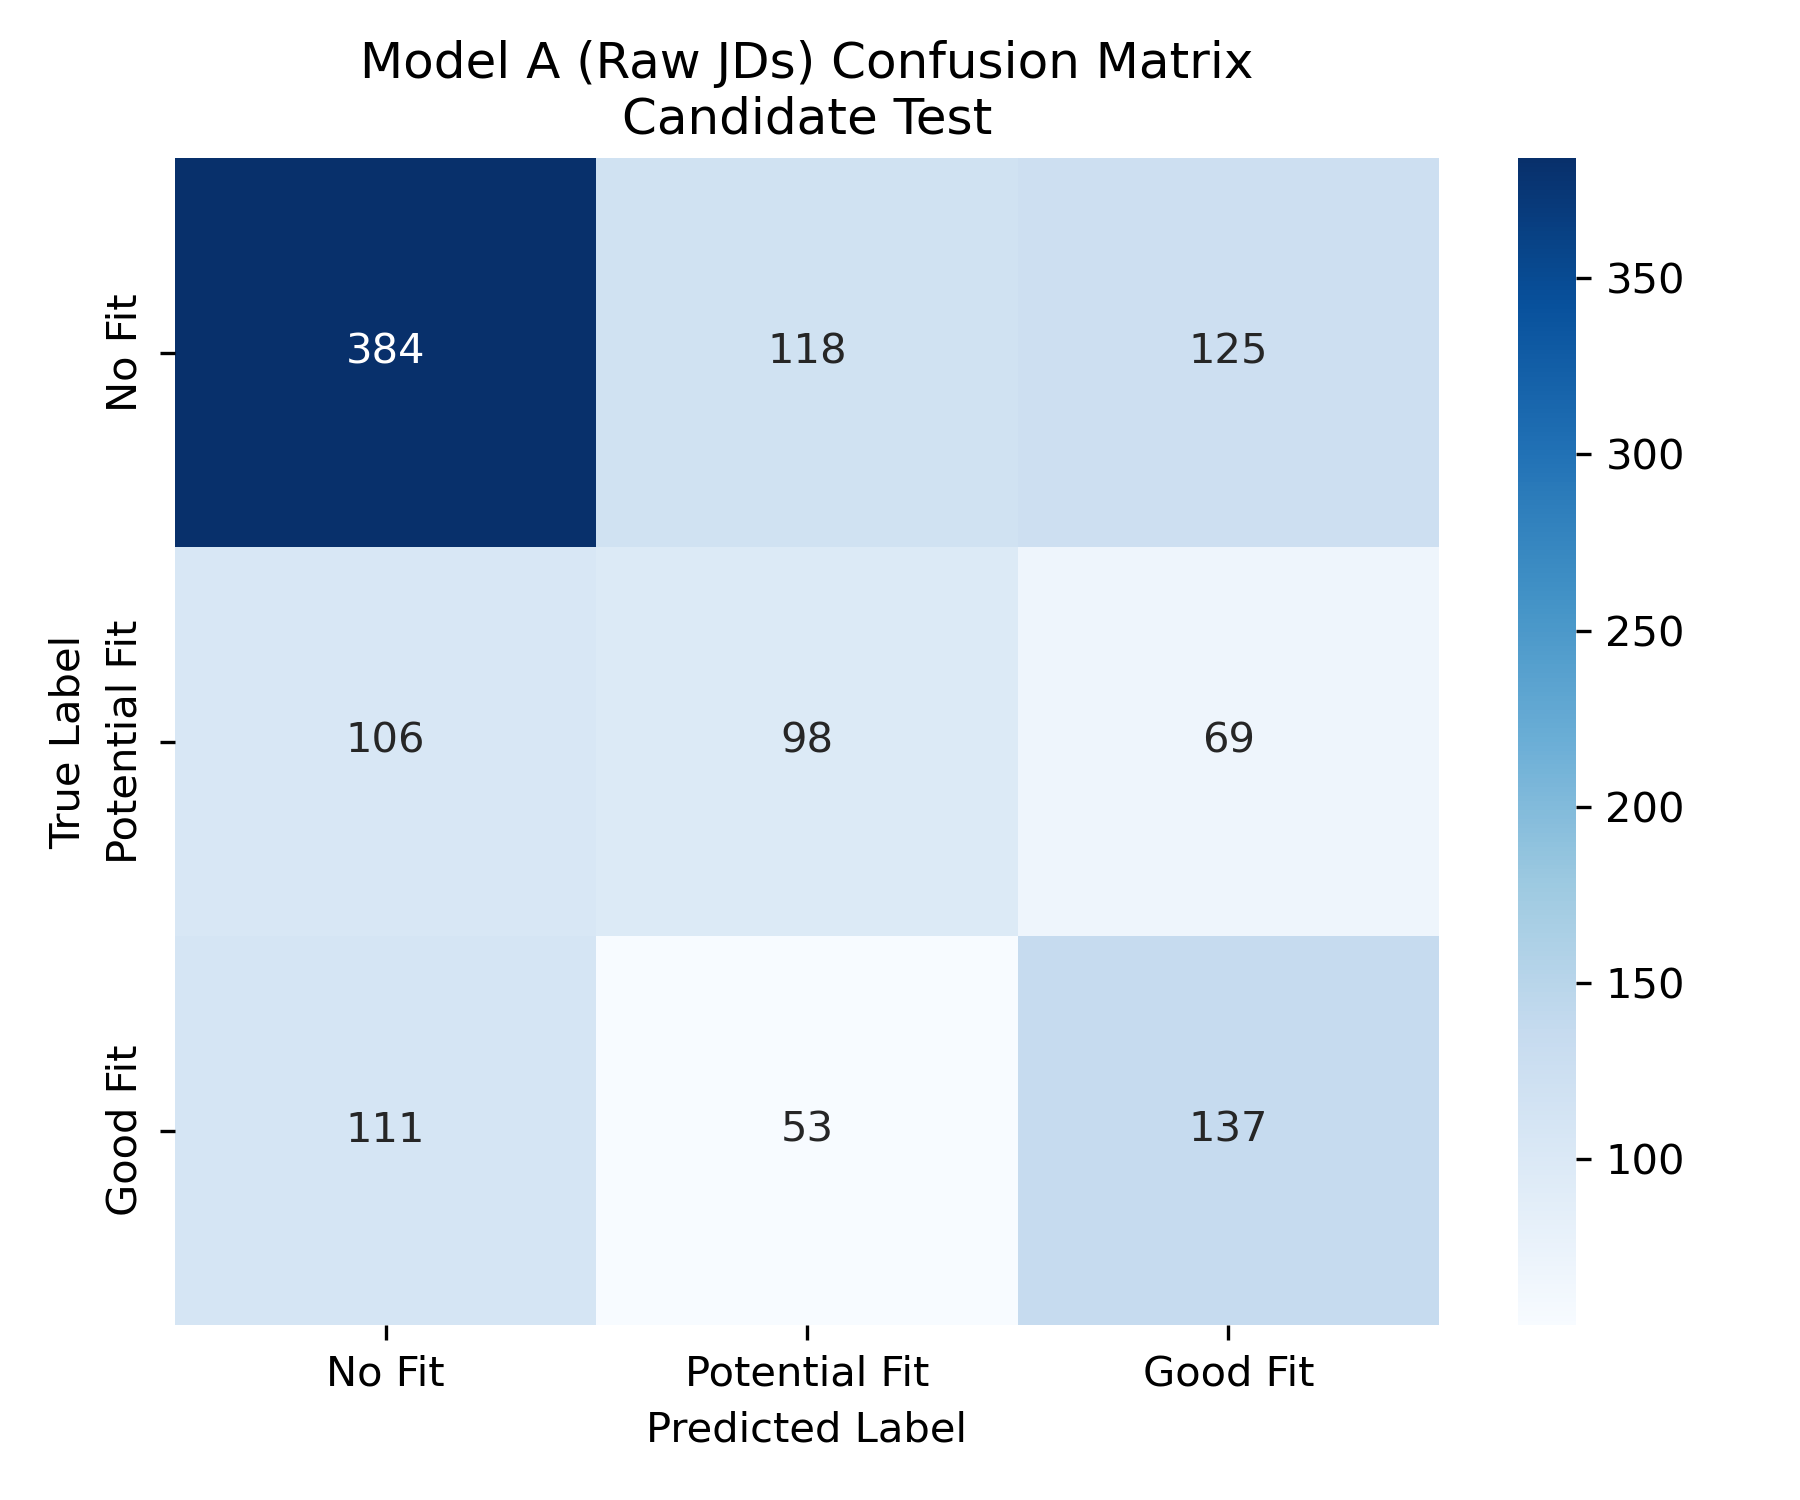

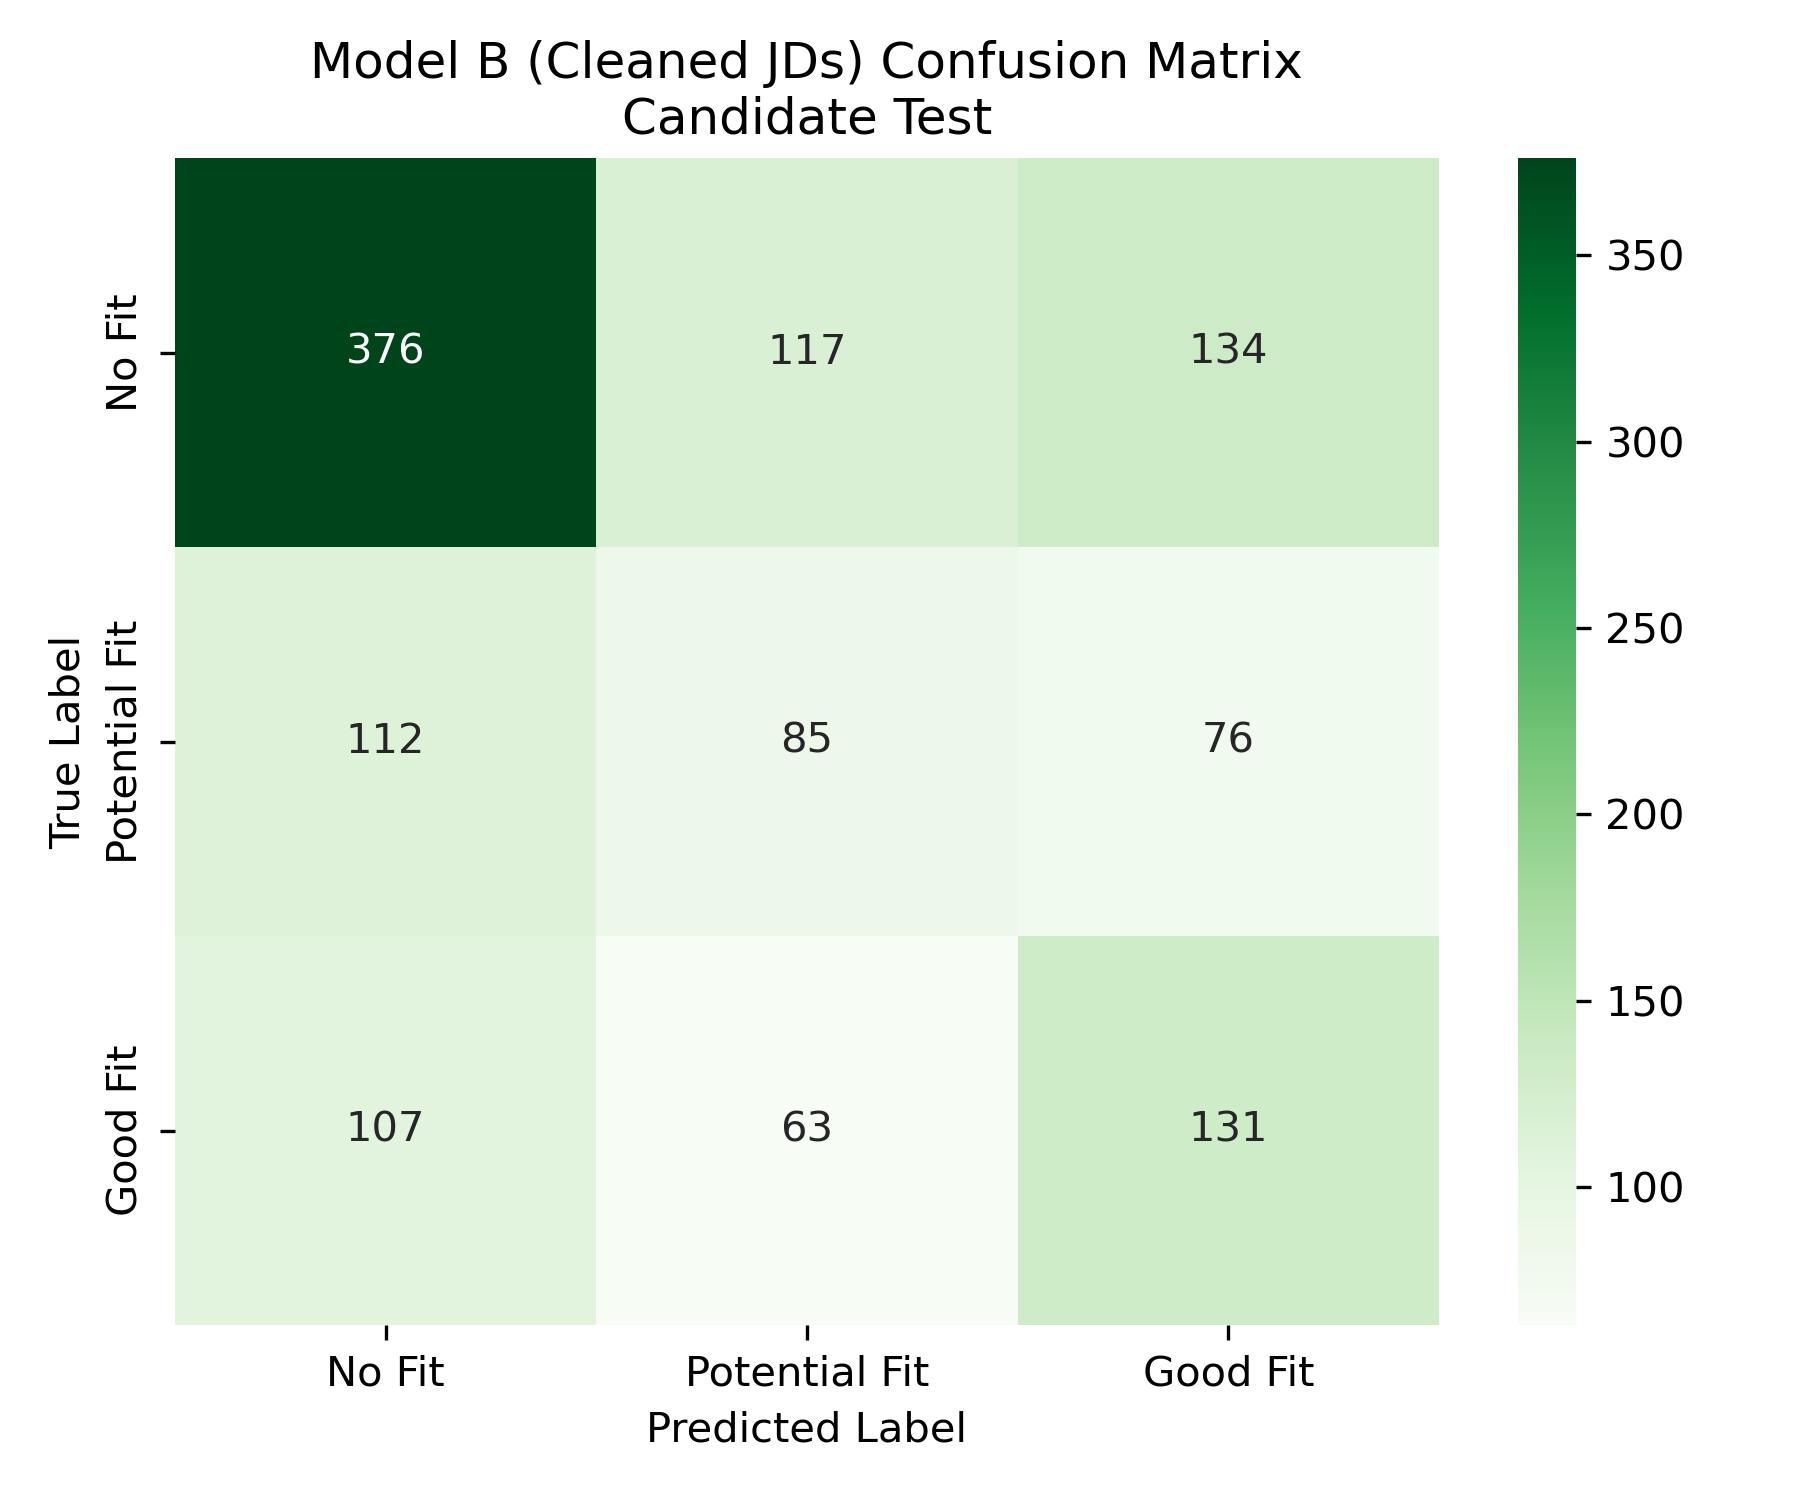

In [7]:
from IPython.display import Image, display

print("Model A (Raw JDs) vs Model B (Cleaned JDs):")
display(Image(filename='../data/evaluation/plots/phase6b_confusion_original.png'))
display(Image(filename='../data/evaluation/plots/phase6b_confusion_cleaned.png'))


## 7. Key Findings & Architectural Verdict

### Empirical Evaluation Summary:
1. **Cleaning Behavior**:
   - 268 of 351 unique job descriptions (76.35%) contained boilerplate that was successfully cleaned.
   - Word count decreased from mean 371.1 to 309.3 (16.6% reduction).
   - Median text retained was 99.5%, mean 86.6%, confirming that the cleaner was conservative and did not aggressively destroy text.
   - Strict fallback was triggered on 3 JDs.

2. **Classification Performance**:
   - **Validation Macro F1**: Model A = `0.4603` vs Model B = `0.4417` ($\Delta = -0.0186$)
   - **Candidate Test Macro F1**: Model A = `0.4735` vs Model B = `0.4465` ($\Delta = -0.0270$)
   - **Candidate Test Accuracy**: Model A = `0.5154` vs Model B = `0.4929` ($\Delta = -0.0225$)
   - **Official Test Macro F1**: Model A = `0.4220` vs Model B = `0.4072` ($\Delta = -0.0148$)
   - **Official Test Accuracy**: Model A = `0.4508` vs Model B = `0.4406` ($\Delta = -0.0102$)

3. **Root Cause Analysis (Why Cleaning Degraded Performance)**:
   - **Net Negative Transitions**: Across 1,201 test pairs, 62 false predictions were recovered, but 89 previously correct predictions regressed (net loss of 27 correct classifications).
   - **Disproportionate Impact on Intermediate Fit (`Potential Fit`)**: `Potential Fit` F1 dropped from 0.3616 to 0.3160 (-4.56%). Trimming context removed borderline lexical overlap signals that differentiated partial matches from No Fits.
   - **Distortion of Calibrated Length Ratios**: In Phase 6A, the linear classifier learned positive/negative calibrated weights on `resume_to_job_word_ratio` and `log_job_word_count`. Shortening JDs shifted these feature distributions away from their learned statistical calibration.
   - **Loss of Implicit Domain Cues**: Broad company introductions ("leading health insurance provider", "fintech startup") often provide domain-level cues that Sentence-BERT dense embeddings leverage, even if corporate legal boilerplate is technically non-technical.

### Architectural Decision:
> **VERDICT**: **Model A (Raw JDs) remains the Reference Model.**
> We do NOT deploy JD cleaning as a mandatory feature-level upstream pipeline for the primary classifier.
> We lock Model A as the reference model and preserve the finding in `DECISIONS.md`.
